# Municipality Market Sale Prices

**How has the median market sale price changed by municipality and year, and which municipalities rose fastest?**

This notebook only reads `output.municipality_year_sales` from DuckDB (run `make run` first).

- A market sale is an assessor-coded valid sale of at least $1,000 that is not part of a multi-parcel deed.
- Prices are nominal US dollars.
- A municipality is ranked for a year only if it has **at least 30 sales in that year and the year before**. The first year is the baseline and has no ranking.

In [ ]:
%matplotlib inline
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
db_path = root / 'data' / 'duckdb' / 'property_sales.duckdb'
if not db_path.is_file():
    raise FileNotFoundError('Run make run from the project root first.')

with duckdb.connect(str(db_path), read_only=True) as connection:
    sales = connection.sql('''
        SELECT * FROM output.municipality_year_sales
        ORDER BY municipality, sale_year
    ''').df()

if sales.empty:
    raise ValueError('The output table is empty. Run make run first.')

first_year = int(sales.sale_year.min())
latest_year = int(sales.sale_year.max())
years = list(range(first_year, latest_year + 1))
sample_totals = sales.groupby('municipality').sale_count.sum().sort_values(ascending=False)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
print(f'{len(sales):,} municipality-years, {sales.municipality_key.nunique()} municipalities, '
      f'{first_year}-{latest_year}, {sales.sale_count.sum():,} qualifying sales.')
display(sales.head())

766 municipality-years, 130 municipalities, 2020-2025, 57,029 qualifying sales.


,municipality_key,municipality,sale_year,sale_count,median_sale_price,low_sample_flag,previous_year_sale_count,previous_year_median_sale_price,yoy_price_change,yoy_percent_change,ranking_eligible,yoy_growth_rank
0,municipality:901,Aleppo,2020,20,226500.0,True,<NA>,NaN,NaN,NaN,False,<NA>
1,municipality:901,Aleppo,2021,13,217500.0,True,20,226500.0,-9000.0,-3.973510,False,<NA>
2,municipality:901,Aleppo,2022,17,250000.0,True,13,217500.0,32500.0,14.942529,False,<NA>
3,municipality:901,Aleppo,2023,10,263970.0,True,17,250000.0,13970.0,5.588000,False,<NA>
4,municipality:901,Aleppo,2024,13,280000.0,True,10,263970.0,16030.0,6.072660,False,<NA>


## 1. How much data supports the comparisons?

Qualifying sales, municipalities with any sale, groups below 30 sales, and municipalities eligible to rank, per year.

In [11]:
coverage = sales.groupby('sale_year').agg(
    included_sales=('sale_count', 'sum'),
    municipalities=('municipality_key', 'nunique'),
    low_sample_groups=('low_sample_flag', 'sum'),
    ranking_eligible=('ranking_eligible', 'sum'),
)
display(coverage)

,included_sales,municipalities,low_sample_groups,ranking_eligible
sale_year,,,,
2020,8206,128,67,0
2021,8802,127,65,59
2022,10999,128,60,62
2023,9923,126,61,63
2024,9583,128,62,64
2025,9516,129,66,62


## 2. How did annual median prices change?

The five municipalities with the most qualifying sales. Years with fewer than 30 sales are left off the chart but shown in the table.

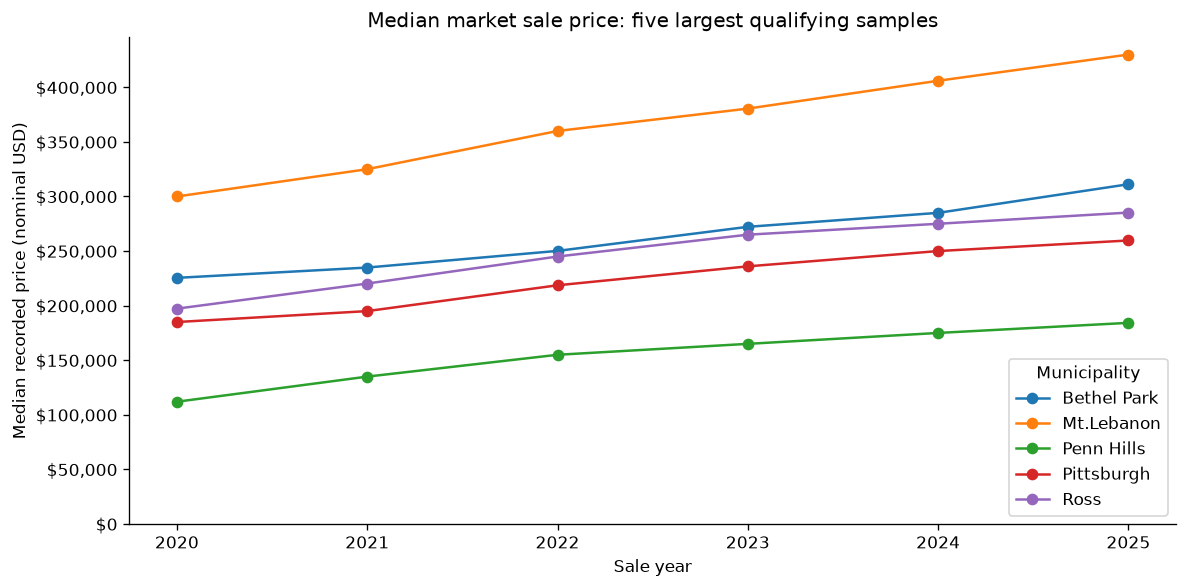

,municipality,sale_year,sale_count,median_sale_price,low_sample_flag
54,Bethel Park,2020,268,225450.0,False
55,Bethel Park,2021,269,234900.0,False
56,Bethel Park,2022,340,250150.0,False
57,Bethel Park,2023,304,272200.0,False
58,Bethel Park,2024,261,285000.0,False
59,Bethel Park,2025,269,311200.0,False
438,Mt.Lebanon,2020,261,300000.0,False
439,Mt.Lebanon,2021,228,325000.0,False
440,Mt.Lebanon,2022,355,360000.0,False
441,Mt.Lebanon,2023,352,380500.0,False


In [12]:
selected_municipalities = sample_totals.head(5).index.tolist()
selected = sales.loc[sales.municipality.isin(selected_municipalities)]
prices = (selected.loc[~selected.low_sample_flag]
          .pivot(index='sale_year', columns='municipality', values='median_sale_price')
          .reindex(years))

axis = prices.plot(marker='o', figsize=(10, 5))
axis.set(title='Median market sale price: five largest qualifying samples',
         xlabel='Sale year', ylabel='Median recorded price (nominal USD)',
         xticks=years, ylim=(0, None))
axis.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
axis.legend(title='Municipality')
plt.tight_layout()
plt.show()
display(selected[['municipality', 'sale_year', 'sale_count',
                  'median_sale_price', 'low_sample_flag']])

## 3. Which municipality rose fastest in each year?

The rank-1 municipality per year (ties included), using the year-over-year change stored in the output table.

In [13]:
eligible = sales.loc[sales.ranking_eligible]
leaders = eligible.loc[eligible.yoy_growth_rank.eq(1)].sort_values(['sale_year', 'municipality'])
ranking_columns = ['sale_year', 'municipality', 'previous_year_sale_count',
                   'sale_count', 'previous_year_median_sale_price',
                   'median_sale_price', 'yoy_percent_change', 'yoy_growth_rank']
price_format = {'previous_year_median_sale_price': '${:,.0f}',
                'median_sale_price': '${:,.0f}', 'yoy_percent_change': '{:+.2f}%'}
if leaders.empty:
    print('No municipality has enough adjacent-year data to rank.')
else:
    display(leaders[ranking_columns].style.format(price_format))

,sale_year,municipality,previous_year_sale_count,sale_count,previous_year_median_sale_price,median_sale_price,yoy_percent_change,yoy_growth_rank
409,2021,McKeesport,61,62,"$40,000","$66,750",+66.88%,1
590,2022,Sewickley,35,57,"$336,000","$500,000",+48.81%,1
334,2023,Indiana,42,44,"$268,750","$376,000",+39.91%,1
406,2024,McKees Rocks,34,40,"$72,500","$111,000",+53.10%,1
413,2025,McKeesport,80,69,"$81,250","$100,000",+23.08%,1


## 4. Fastest risers in the latest year

Top 10 ranks (ties kept). Check the sale counts and starting prices in the table: a large percentage from a low base can be a small dollar change.

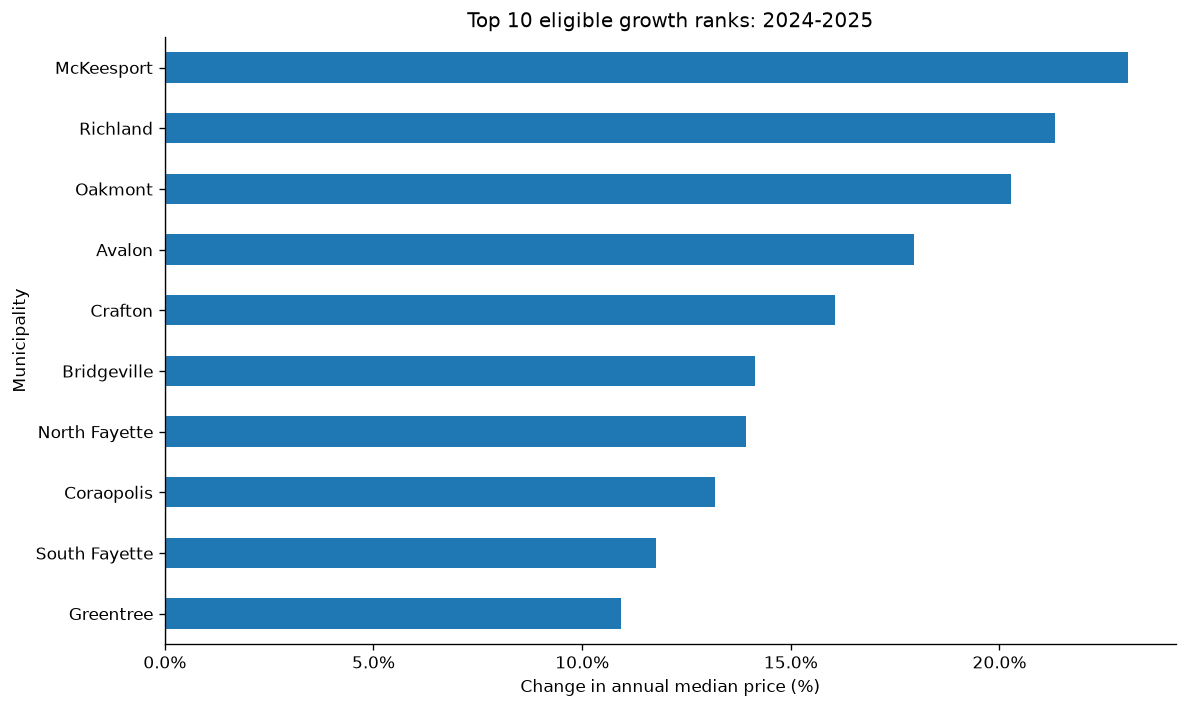

,sale_year,municipality,previous_year_sale_count,sale_count,previous_year_median_sale_price,median_sale_price,yoy_percent_change,yoy_growth_rank
413,2025,McKeesport,80,69,"$81,250","$100,000",+23.08%,1
563,2025,Richland,95,99,"$366,800","$445,000",+21.32%,2
491,2025,Oakmont,72,72,"$291,000","$350,000",+20.27%,3
17,2025,Avalon,42,40,"$195,000","$230,000",+17.95%,4
155,2025,Crafton,38,36,"$202,500","$235,000",+16.05%,5
101,2025,Bridgeville,43,45,"$205,000","$234,000",+14.15%,6
467,2025,North Fayette,116,114,"$305,000","$347,500",+13.93%,7
149,2025,Coraopolis,47,36,"$163,000","$184,500",+13.19%,8
623,2025,South Fayette,207,185,"$340,000","$380,000",+11.76%,9
296,2025,Greentree,49,54,"$293,000","$325,000",+10.92%,10


In [14]:
latest_eligible = eligible.loc[eligible.sale_year.eq(latest_year)]
top_growth = latest_eligible.loc[latest_eligible.yoy_growth_rank.le(10)].sort_values(
    ['yoy_percent_change', 'municipality']
)
if top_growth.empty:
    print(f'No ranking-eligible municipalities in {latest_year}.')
else:
    colors = ['tab:blue' if change >= 0 else 'tab:red' for change in top_growth.yoy_percent_change]
    axis = top_growth.plot.barh(x='municipality', y='yoy_percent_change',
                                color=colors, legend=False, figsize=(10, 6))
    axis.axvline(0, color='gray', linewidth=0.8)
    axis.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    axis.set(title=f'Top 10 eligible growth ranks: {latest_year - 1}-{latest_year}',
             xlabel='Change in annual median price (%)', ylabel='Municipality')
    plt.tight_layout()
    plt.show()
    display(top_growth.sort_values(['yoy_growth_rank', 'municipality'])[
        ranking_columns
    ].style.format(price_format))

## 5. Overall direction across the period

How many municipalities have a higher median in the latest year than in the first, among those with at least 30 sales in both years.

In [15]:
annual_medians = sales.pivot(index='municipality', columns='sale_year', values='median_sale_price')
annual_counts = sales.pivot(index='municipality', columns='sale_year', values='sale_count')
endpoint_years = [first_year, latest_year]
endpoints = annual_medians[endpoint_years].where(annual_counts[endpoint_years].ge(30)).dropna()
change = endpoints[latest_year] - endpoints[first_year]
print(f'{len(endpoints)} municipalities have at least 30 sales in both {first_year} and {latest_year}.')
print(f'Median price rose in {(change > 0).sum()}, fell in {(change < 0).sum()}, '
      f'and was unchanged in {(change == 0).sum()}.')

61 municipalities have at least 30 sales in both 2020 and 2025.
Median price rose in 61, fell in 0, and was unchanged in 0.


## Limitations

- **Property mix:** different properties sell each year, so a change in median is not the same as appreciation of a given home.
- **Nominal prices:** no inflation adjustment.
- **Small samples:** 30 sales is a practical minimum, not a guarantee of precision.
- **Selection:** counts cover the filtered sample, not total market activity. A few sales with unknown deed references are kept (flagged) since they can't be checked for multiple parcels.
- **Source coding:** the series starts in 2020 to avoid the earlier sale-code change.
- **Late recordings:** refreshed data can still change completed years.

## Appendix: every municipality

All municipalities, including low-sample groups. Read medians alongside sale counts; `-` means no qualifying sales.

In [16]:
print('Annual median prices (nominal USD)')
display(annual_medians.sort_index().style.format('${:,.0f}', na_rep='-'))
print('Qualifying sales per municipality and year')
display(annual_counts.sort_index().style.format('{:,.0f}', na_rep='-'))

Annual median prices (nominal USD)


sale_year,2020,2021,2022,2023,2024,2025
municipality,,,,,,
Aleppo,"$226,500","$217,500","$250,000","$263,970","$280,000","$322,500"
Aspinwall,"$317,450","$375,000","$370,000","$353,750","$415,000","$414,000"
Avalon,"$130,000","$162,500","$198,750","$209,500","$195,000","$230,000"
Baldwin Boro,"$164,900","$185,000","$200,000","$201,500","$217,000","$228,400"
Baldwin Twp,"$164,500","$172,250","$219,900","$169,900","$230,000","$226,000"
Bell Acres,"$537,188","$310,000","$267,000","$680,000","$675,000","$755,000"
Bellevue,"$145,000","$182,500","$200,000","$240,000","$239,938","$240,000"
Ben Avon,"$270,000","$227,925","$351,250","$337,200","$387,500","$325,000"
Ben Avon Heights,"$471,750","$361,300","$775,000","$388,500","$575,000","$534,950"


Qualifying sales per municipality and year


sale_year,2020,2021,2022,2023,2024,2025
municipality,,,,,,
Aleppo,20,13,17,10,13,19
Aspinwall,20,15,29,22,19,23
Avalon,37,32,51,46,42,40
Baldwin Boro,149,153,182,168,191,187
Baldwin Twp,13,18,21,18,17,23
Bell Acres,22,8,13,11,15,11
Bellevue,27,41,47,69,42,47
Ben Avon,25,15,10,20,16,13
Ben Avon Heights,4,1,1,2,1,4
